# Dự đoán thu nhập (Adult Income) & Phân tích/Giảm thiểu thiên vị thuật toán

**Bài toán:** Dự đoán một cá nhân có thu nhập hằng năm trên 50.000 USD hay không, dựa trên dữ liệu
census Adult Income (UCI). Bên cạnh việc tối ưu độ chính xác, notebook này tập trung vào việc
**phát hiện và giảm thiểu thiên vị thuật toán (algorithmic bias)** theo hai thuộc tính nhạy cảm:
`sex` (giới tính) và `race` (chủng tộc), sử dụng thư viện [`fairlearn`](https://fairlearn.org/).

**Cấu trúc notebook:**
1. Nạp & làm sạch dữ liệu
2. Pipeline tiền xử lý
3. Cross-Validation + Hyperparameter Tuning (`RandomizedSearchCV`)
4. Đánh giá mô hình Baseline (đã tuning) trên tập test
5. Đo lường Fairness với `fairlearn.metrics.MetricFrame` (sex, race, và **giao nhau sex × race**)
6. Giảm thiểu bias bằng `fairlearn.reductions.ExponentiatedGradient`
7. So sánh trước/sau & phân tích trade-off Demographic Parity vs Equalized Odds
8. Model Interpretability với **SHAP** — tìm đặc trưng nào đóng vai trò "proxy" cho sex/race
9. Kết luận & giới hạn của dự án


## 1. Nạp & làm sạch dữ liệu

Dữ liệu gốc dùng ký tự `"?"` để biểu diễn giá trị thiếu ở các cột `workclass`, `occupation`,
`native.country`. Ta thay các giá trị này bằng `NaN` rồi loại bỏ các dòng thiếu dữ liệu.

Nhãn mục tiêu `income_label` = 1 nếu thu nhập `>50K`, ngược lại = 0.


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, RandomizedSearchCV, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, roc_auc_score, classification_report

!pip install fairlearn
from fairlearn.metrics import (
    MetricFrame,
    selection_rate,
    true_positive_rate,
    false_positive_rate,
    demographic_parity_difference,
    equalized_odds_difference,
)
from fairlearn.reductions import ExponentiatedGradient, DemographicParity

import shap

RANDOM_STATE = 42
pd.set_option("display.float_format", lambda v: f"{v:0.4f}")

In [ ]:
df = pd.read_csv("adult_income.csv")
df = df.replace("?", np.nan)
n_before = len(df)
df = df.dropna()
n_after = len(df)
print(f"So dong truoc/sau khi loai missing: {n_before} -> {n_after} (mat {n_before - n_after} dong, "
      f"{(n_before - n_after) / n_before:.1%})")

df["income_label"] = (df["income"] == ">50K").astype(int)
df["income_label"].value_counts(normalize=True).rename("ty le").to_frame()

So dong truoc/sau khi loai missing: 32561 -> 30162 (mat 2399 dong, 7.4%)


,ty le
income_label,
0,0.7511
1,0.2489


In [ ]:
numeric_features = ["age", "education.num", "capital.gain", "capital.loss", "hours.per.week"]
categorical_features = ["workclass", "education", "marital.status", "occupation", "relationship"]
feature_cols = numeric_features + categorical_features

X = df[feature_cols].copy()
y = df["income_label"].copy()
sensitive = df[["sex", "race"]].copy()

X_train, X_test, y_train, y_test, A_train, A_test = train_test_split(
    X, y, sensitive, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

# Ket hop sex x race de phan tich fairness giao nhau (intersectional) o phan 5
A_train["sex_race"] = A_train["sex"] + " & " + A_train["race"]
A_test["sex_race"] = A_test["sex"] + " & " + A_test["race"]

print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (24129, 10)  Test: (6033, 10)


## 2. Pipeline tiền xử lý

Thay vì `LabelEncoder` (tạo quan hệ thứ tự giả cho biến hạng mục) fit trên toàn bộ dữ liệu trước khi
chia train/test (rò rỉ thông tin phân phối), dùng `ColumnTransformer` + `OneHotEncoder` đặt trong
một `sklearn.Pipeline`. Pipeline chỉ được `fit` trên `X_train`, đảm bảo không có thông tin từ tập
test rò rỉ vào bước tiền xử lý, và xử lý được category chưa từng thấy (`handle_unknown="ignore"`)
khi triển khai thực tế.


In [ ]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", "passthrough", numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
    ]
)
print("Preprocessor da san sang.")

Preprocessor da san sang.


## 3. Cross-Validation & Hyperparameter Tuning


In [ ]:
tuning_pipeline = Pipeline(steps=[
    ("prep", preprocessor),
    ("clf", RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1)),
])

param_distributions = {
    "clf__n_estimators": [100, 150, 200],
    "clf__max_depth": [8, 12, 16],
    "clf__min_samples_leaf": [1, 2, 4],
}

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

search = RandomizedSearchCV(
    tuning_pipeline,
    param_distributions=param_distributions,
    n_iter=6,
    cv=cv,
    scoring="roc_auc",
    random_state=RANDOM_STATE,
    n_jobs=1,
    verbose=0,
)
search.fit(X_train, y_train)

print("Best params:", search.best_params_)
print(f"Best CV AUC: {search.best_score_:.4f}")

cv_results = pd.DataFrame(search.cv_results_)[
    ["params", "mean_test_score", "std_test_score", "rank_test_score"]
].sort_values("rank_test_score")
cv_results

Best params: {'clf__n_estimators': 100, 'clf__min_samples_leaf': 2, 'clf__max_depth': 16}
Best CV AUC: 0.9126


,params,mean_test_score,std_test_score,rank_test_score
3,"{'clf__n_estimators': 100, 'clf__min_samples_l...",0.9126,0.0055,1
5,"{'clf__n_estimators': 200, 'clf__min_samples_l...",0.9113,0.0055,2
1,"{'clf__n_estimators': 150, 'clf__min_samples_l...",0.9109,0.0054,3
2,"{'clf__n_estimators': 100, 'clf__min_samples_l...",0.9108,0.0056,4
0,"{'clf__n_estimators': 200, 'clf__min_samples_l...",0.9054,0.0053,5
4,"{'clf__n_estimators': 100, 'clf__min_samples_l...",0.9053,0.0057,6


## 4. Đánh giá mô hình Baseline (đã tuning) trên tập test

In [ ]:
baseline_pipeline = search.best_estimator_

y_pred = baseline_pipeline.predict(X_test)
y_proba = baseline_pipeline.predict_proba(X_test)[:, 1]

acc = accuracy_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_proba)

print(f"Accuracy: {acc:.4f}")
print(f"AUC:      {auc:.4f}\n")
print(classification_report(y_test, y_pred, target_names=["<=50K", ">50K"]))

Accuracy: 0.8669
AUC:      0.9239

              precision    recall  f1-score   support

       <=50K       0.88      0.95      0.91      4531
        >50K       0.80      0.62      0.70      1502

    accuracy                           0.87      6033
   macro avg       0.84      0.78      0.81      6033
weighted avg       0.86      0.87      0.86      6033



## 5. Đo lường Fairness với `fairlearn` (sex, race, và giao nhau sex × race)

Ba định nghĩa fairness được dùng trong notebook này:

- **Selection rate**: tỉ lệ được dự đoán là `>50K` trong mỗi nhóm.
- **Demographic Parity difference (DP diff)**: chênh lệch selection rate lớn nhất giữa các nhóm.
  DP diff = 0 nghĩa là model dự đoán ">50K" với tỉ lệ như nhau cho mọi nhóm, **bất kể** nhãn thật.
- **Equalized Odds difference (EO diff)**: chênh lệch lớn nhất giữa các nhóm, xét **cả** True
  Positive Rate (TPR — "Equal Opportunity") **và** False Positive Rate (FPR).

Bên cạnh phân tích theo từng thuộc tính riêng lẻ, ta bổ sung phân tích **giao nhau (intersectional)**
theo tổ hợp `sex × race` — vì một nhóm có thể "trông công bằng" khi xét riêng từng thuộc tính, nhưng
lại chịu thiệt thòi rõ rệt khi xét đồng thời cả hai (ví dụ: "Nữ + Black" có thể bị đối xử khác biệt
hơn nhiều so với gộp chung "tất cả Nữ" hoặc "tất cả Black").


In [ ]:
def fairness_table(y_true, y_pred, sensitive_col, label):
    mf = MetricFrame(
        metrics={
            "selection_rate": selection_rate,
            "tpr (recall)": true_positive_rate,
            "fpr": false_positive_rate,
        },
        y_true=y_true,
        y_pred=y_pred,
        sensitive_features=sensitive_col,
    )
    print(f"=== Fairness theo '{label}' ===")
    display(mf.by_group)
    dp = demographic_parity_difference(y_true, y_pred, sensitive_features=sensitive_col)
    eod = equalized_odds_difference(y_true, y_pred, sensitive_features=sensitive_col)
    print(f"Demographic Parity diff : {dp:.4f}")
    print(f"Equalized Odds diff     : {eod:.4f}\n")
    return dp, eod

dp_sex_base, eod_sex_base = fairness_table(y_test, y_pred, A_test["sex"], "sex")
dp_race_base, eod_race_base = fairness_table(y_test, y_pred, A_test["race"], "race")

=== Fairness theo 'sex' ===


,selection_rate,tpr (recall),fpr
sex,,,
Female,0.0861,0.5901,0.0205
Male,0.2405,0.6211,0.0680


Demographic Parity diff : 0.1544
Equalized Odds diff     : 0.0475

=== Fairness theo 'race' ===


,selection_rate,tpr (recall),fpr
race,,,
Amer-Indian-Eskimo,0.1136,0.5714,0.0270
Asian-Pac-Islander,0.2402,0.6818,0.0963
Black,0.0989,0.5488,0.0211
Other,0.0196,0.0000,0.0208
White,0.2016,0.6201,0.0526


Demographic Parity diff : 0.2206
Equalized Odds diff     : 0.6818



In [ ]:
# Fairness giao nhau: sex x race. Mot so nhom co rat it mau (vi du Amer-Indian-Eskimo Female)
# nen selection_rate/TPR/FPR o cac nhom nay co the khong on dinh - can doc ket qua voi luu y ve co mau.
group_sizes = A_test["sex_race"].value_counts()
print("So mau moi nhom giao nhau (sex x race):")
display(group_sizes.to_frame("n_samples"))

dp_inter, eod_inter = fairness_table(y_test, y_pred, A_test["sex_race"], "sex x race (giao nhau)")

So mau moi nhom giao nhau (sex x race):


,n_samples
sex_race,
Male & White,3651
Female & White,1552
Female & Black,284
Male & Black,272
Male & Asian-Pac-Islander,122
Female & Asian-Pac-Islander,57
Male & Other,32
Male & Amer-Indian-Eskimo,27
Female & Other,19


=== Fairness theo 'sex x race (giao nhau)' ===


,selection_rate,tpr (recall),fpr
sex_race,,,
Female & Amer-Indian-Eskimo,0.1176,1.0000,0.0000
Female & Asian-Pac-Islander,0.1579,0.5000,0.1020
Female & Black,0.0528,0.5417,0.0077
Female & Other,0.0000,0.0000,0.0000
Female & White,0.0902,0.5989,0.0205
Male & Amer-Indian-Eskimo,0.1111,0.4000,0.0455
Male & Asian-Pac-Islander,0.2787,0.7222,0.0930
Male & Black,0.1471,0.5517,0.0374
Male & Other,0.0312,0.0000,0.0333


Demographic Parity diff : 0.2787
Equalized Odds diff     : 1.0000



## 6. Giảm thiểu bias với `fairlearn.reductions.ExponentiatedGradient`



In [ ]:
best_params = search.best_params_

mitigator_estimator = Pipeline(steps=[
    ("prep", preprocessor),
    ("clf", RandomForestClassifier(
        n_estimators=best_params["clf__n_estimators"],
        max_depth=best_params["clf__max_depth"],
        min_samples_leaf=best_params["clf__min_samples_leaf"],
        random_state=RANDOM_STATE, n_jobs=-1,
    )),
])

mitigator = ExponentiatedGradient(
    estimator=mitigator_estimator,
    constraints=DemographicParity(),
    sample_weight_name="clf__sample_weight",
    max_iter=30,
)

mitigator.fit(X_train, y_train, sensitive_features=A_train["sex"])
y_pred_mit = mitigator.predict(X_test)

acc_mit = accuracy_score(y_test, y_pred_mit)
print(f"Accuracy sau mitigation: {acc_mit:.4f}  (baseline: {acc:.4f}, chenh lech {acc_mit - acc:+.4f})")

Accuracy sau mitigation: 0.8460  (baseline: 0.8669, chenh lech -0.0209)


In [ ]:
dp_sex_mit, eod_sex_mit = fairness_table(y_test, y_pred_mit, A_test["sex"], "sex (sau mitigation)")
dp_race_mit, eod_race_mit = fairness_table(y_test, y_pred_mit, A_test["race"], "race (sau mitigation)")
dp_inter_mit, eod_inter_mit = fairness_table(y_test, y_pred_mit, A_test["sex_race"], "sex x race (sau mitigation)")

=== Fairness theo 'sex (sau mitigation)' ===


,selection_rate,tpr (recall),fpr
sex,,,
Female,0.1628,0.7748,0.0832
Male,0.1650,0.4766,0.0237


Demographic Parity diff : 0.0022
Equalized Odds diff     : 0.2982

=== Fairness theo 'race (sau mitigation)' ===


,selection_rate,tpr (recall),fpr
race,,,
Amer-Indian-Eskimo,0.1136,0.5714,0.0270
Asian-Pac-Islander,0.1732,0.4318,0.0889
Black,0.1205,0.5000,0.0549
Other,0.0784,0.0000,0.0833
White,0.1699,0.5256,0.0433


Demographic Parity diff : 0.0948
Equalized Odds diff     : 0.5714

=== Fairness theo 'sex x race (sau mitigation)' ===


,selection_rate,tpr (recall),fpr
sex_race,,,
Female & Amer-Indian-Eskimo,0.1176,1.0000,0.0000
Female & Asian-Pac-Islander,0.2281,0.6250,0.1633
Female & Black,0.1408,0.6667,0.0923
Female & Other,0.1579,0.0000,0.1667
Female & White,0.1649,0.7968,0.0784
Male & Amer-Indian-Eskimo,0.1111,0.4000,0.0455
Male & Asian-Pac-Islander,0.1475,0.3889,0.0465
Male & Black,0.0993,0.4310,0.0093
Male & Other,0.0312,0.0000,0.0333


Demographic Parity diff : 0.1968
Equalized Odds diff     : 1.0000



## 7. So sánh trước / sau & phân tích Trade-off

In [ ]:
summary = pd.DataFrame({
    "Accuracy": [acc, acc_mit],
    "DP diff (sex)": [dp_sex_base, dp_sex_mit],
    "EO diff (sex)": [eod_sex_base, eod_sex_mit],
    "DP diff (race)": [dp_race_base, dp_race_mit],
    "EO diff (race)": [eod_race_base, eod_race_mit],
    "DP diff (sex x race)": [dp_inter, dp_inter_mit],
    "EO diff (sex x race)": [eod_inter, eod_inter_mit],
}, index=["Baseline (tuned)", "Sau mitigation (ExponentiatedGradient, DP theo sex)"])
summary

,Accuracy,DP diff (sex),EO diff (sex),DP diff (race),EO diff (race),DP diff (sex x race),EO diff (sex x race)
Baseline (tuned),0.8669,0.1544,0.0475,0.2206,0.6818,0.2787,1.0000
"Sau mitigation (ExponentiatedGradient, DP theo sex)",0.8460,0.0022,0.2982,0.0948,0.5714,0.1968,1.0000


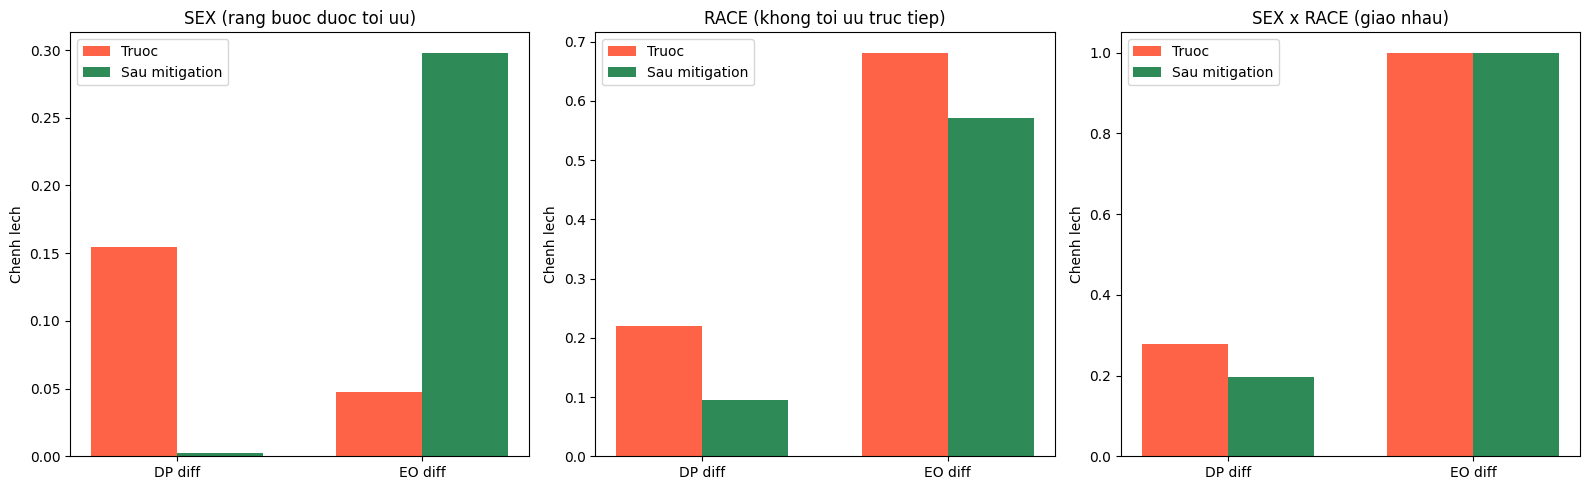

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

labels = ["DP diff", "EO diff"]
x = np.arange(len(labels))
w = 0.35

panels = [
    ("SEX (rang buoc duoc toi uu)", [dp_sex_base, eod_sex_base], [dp_sex_mit, eod_sex_mit]),
    ("RACE (khong toi uu truc tiep)", [dp_race_base, eod_race_base], [dp_race_mit, eod_race_mit]),
    ("SEX x RACE (giao nhau)", [dp_inter, eod_inter], [dp_inter_mit, eod_inter_mit]),
]

for ax, (title, before, after) in zip(axes, panels):
    ax.bar(x - w/2, before, w, label="Truoc", color="tomato")
    ax.bar(x + w/2, after, w, label="Sau mitigation", color="seagreen")
    ax.set_xticks(x); ax.set_xticklabels(labels)
    ax.set_title(title)
    ax.set_ylabel("Chenh lech")
    ax.legend()

plt.tight_layout()
plt.savefig("fairness_before_after.png", dpi=120)
plt.show()

## 8. Model Interpretability với SHAP — tìm đặc trưng "proxy" cho sex/race

Câu hỏi đặt ra: **đặc
trưng nào trong 11 đặc trưng model đang dùng đóng vai trò "proxy" mạnh nhất, gián tiếp mang thông
tin về sex/race?**

Dùng `shap.TreeExplainer` để tính SHAP values cho model baseline (đã tuning), sau đó:
1. Xếp hạng tầm quan trọng trung bình của từng đặc trưng (global feature importance theo SHAP).
2. Với các đặc trưng hạng đầu, kiểm tra tương quan/phân phối của chúng theo `sex` và `race` bằng
   crosstab — đặc trưng nào vừa quan trọng với model, vừa phân bố lệch mạnh theo sex/race, chính là
   "proxy" khả nghi nhất.

> Để notebook chạy nhanh, SHAP được tính trên một mẫu con 500 dòng ngẫu nhiên của tập test thay vì
> toàn bộ — đủ để ước lượng ổn định thứ hạng tầm quan trọng trung bình.


In [ ]:
rng = np.random.RandomState(RANDOM_STATE)
sample_idx = rng.choice(X_test.index, size=min(500, len(X_test)), replace=False)
X_shap = X_test.loc[sample_idx]

fitted_preprocessor = baseline_pipeline.named_steps["prep"]
X_shap_encoded = fitted_preprocessor.transform(X_shap)
if hasattr(X_shap_encoded, "toarray"):
    X_shap_encoded = X_shap_encoded.toarray()

feature_names = numeric_features + list(
    fitted_preprocessor.named_transformers_["cat"].get_feature_names_out(categorical_features)
)

rf_model = baseline_pipeline.named_steps["clf"]
explainer = shap.TreeExplainer(rf_model)
shap_values = explainer.shap_values(X_shap_encoded)

# shap_values co dang (n_samples, n_features, n_classes) trong ban shap moi; lay class ">50K" (index 1)
if isinstance(shap_values, list):
    sv_pos = shap_values[1]
else:
    sv_pos = shap_values[:, :, 1] if shap_values.ndim == 3 else shap_values

mean_abs_shap = pd.Series(np.abs(sv_pos).mean(axis=0), index=feature_names).sort_values(ascending=False)
print("Top 10 dac trung quan trong nhat theo SHAP (gia tri tuyet doi trung binh):")
mean_abs_shap.head(10)

Top 10 dac trung quan trong nhat theo SHAP (gia tri tuyet doi trung binh):


,0
marital.status_Married-civ-spouse,0.0766
education.num,0.0450
capital.gain,0.0421
age,0.0366
relationship_Husband,0.0351
hours.per.week,0.0281
marital.status_Never-married,0.0247
occupation_Exec-managerial,0.0173
occupation_Prof-specialty,0.0122
capital.loss,0.0121


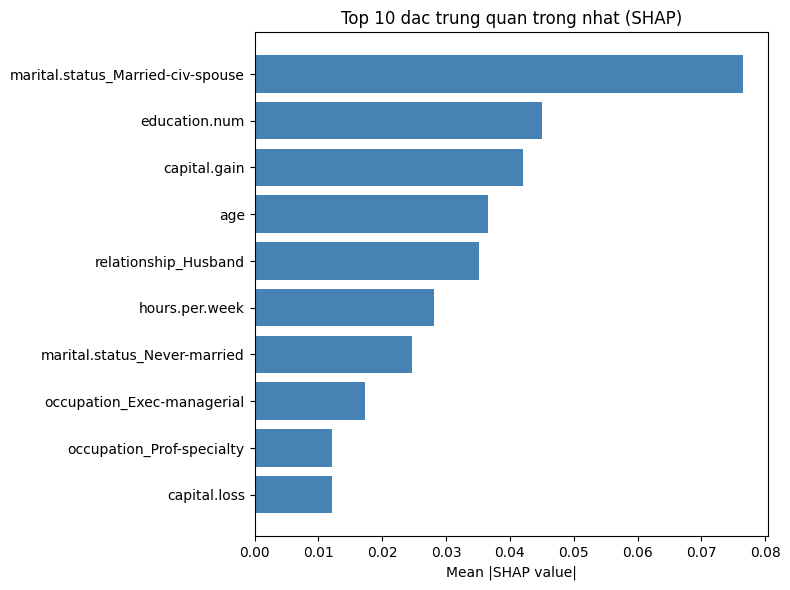

In [ ]:
fig, ax = plt.subplots(figsize=(8, 6))
top10 = mean_abs_shap.head(10).sort_values()
ax.barh(top10.index, top10.values, color="steelblue")
ax.set_xlabel("Mean |SHAP value|")
ax.set_title("Top 10 dac trung quan trong nhat (SHAP)")
plt.tight_layout()
plt.savefig("shap_top_features.png", dpi=120)
plt.show()

In [ ]:
# Kiem tra cac dac trung goc (chua one-hot) co ten xuat hien trong top-10 SHAP,
# xem phan bo cua chung theo sex va race co lech manh khong -> ung vien "proxy".
top_raw_features = sorted({f.split("_")[0] for f in mean_abs_shap.head(10).index if f in numeric_features}
                           | {c for c in categorical_features
                              for f in mean_abs_shap.head(10).index if f.startswith(c + "_")})
print("Cac dac trung goc xuat hien trong top-10 SHAP:", top_raw_features)

for feat in [f for f in top_raw_features if f in categorical_features]:
    print(f"\n--- Phan bo '{feat}' theo sex (%) ---")
    display((pd.crosstab(df[feat], df["sex"], normalize="columns") * 100).round(1))
    print(f"--- Phan bo '{feat}' theo race (%) ---")
    display((pd.crosstab(df[feat], df["race"], normalize="columns") * 100).round(1))

Cac dac trung goc xuat hien trong top-10 SHAP: ['age', 'capital.gain', 'capital.loss', 'education.num', 'hours.per.week', 'marital.status', 'occupation', 'relationship']

--- Phan bo 'marital.status' theo sex (%) ---


sex,Female,Male
marital.status,,
Divorced,25.9000,8.3000
Married-AF-spouse,0.1000,0.0000
Married-civ-spouse,15.1000,61.8000
Married-spouse-absent,1.9000,0.9000
Never-married,44.1000,26.6000
Separated,5.9000,1.8000
Widowed,7.0000,0.7000


--- Phan bo 'marital.status' theo race (%) ---


race,Amer-Indian-Eskimo,Asian-Pac-Islander,Black,Other,White
marital.status,,,,,
Divorced,18.9000,7.5000,16.0000,10.0000,14.0000
Married-AF-spouse,0.0000,0.0000,0.0000,0.0000,0.1000
Married-civ-spouse,38.1000,49.4000,27.2000,39.8000,48.8000
Married-spouse-absent,2.8000,3.7000,1.9000,6.1000,1.0000
Never-married,33.2000,35.1000,42.5000,36.4000,31.0000
Separated,3.5000,2.0000,8.5000,5.6000,2.5000
Widowed,3.5000,2.3000,3.8000,2.2000,2.6000



--- Phan bo 'occupation' theo sex (%) ---


...

race,Amer-Indian-Eskimo,Asian-Pac-Islander,Black,Other,White
occupation,,,,,
Adm-clerical,10.8000,15.0000,17.0000,10.0000,11.8000
Armed-Forces,0.3000,0.0000,0.0000,0.0000,0.0000
Craft-repair,15.4000,9.3000,8.3000,10.8000,14.1000
Exec-managerial,10.5000,13.5000,8.3000,4.8000,13.9000
Farming-fishing,3.5000,1.8000,1.5000,4.8000,3.5000
Handlers-cleaners,7.7000,2.5000,6.0000,4.8000,4.3000
Machine-op-inspct,6.6000,5.6000,9.5000,16.9000,6.1000
Other-service,11.5000,13.1000,19.6000,16.0000,9.5000
Priv-house-serv,0.0000,0.4000,1.0000,1.3000,0.4000



--- Phan bo 'relationship' theo sex (%) ---


sex,Female,Male
relationship,,
Husband,0.0000,61.1000
Not-in-family,36.5000,20.4000
Other-relative,3.9000,2.5000
Own-child,20.0000,12.3000
Unmarried,25.2000,3.7000
Wife,14.4000,0.0000


--- Phan bo 'relationship' theo race (%) ---


race,Amer-Indian-Eskimo,Asian-Pac-Islander,Black,Other,White
relationship,,,,,
Husband,30.8000,40.0000,22.0000,31.6000,43.7000
Not-in-family,25.2000,20.9000,26.0000,25.1000,25.7000
Other-relative,3.8000,7.6000,5.2000,10.8000,2.5000
Own-child,15.0000,16.2000,17.2000,12.6000,14.5000
Unmarried,19.2000,9.1000,24.8000,15.2000,9.0000
Wife,5.9000,6.3000,4.7000,4.8000,4.6000
